Name: Asif Mohammadi (yrq8vu)

Used Claude Code to generate the codes and plots.

# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


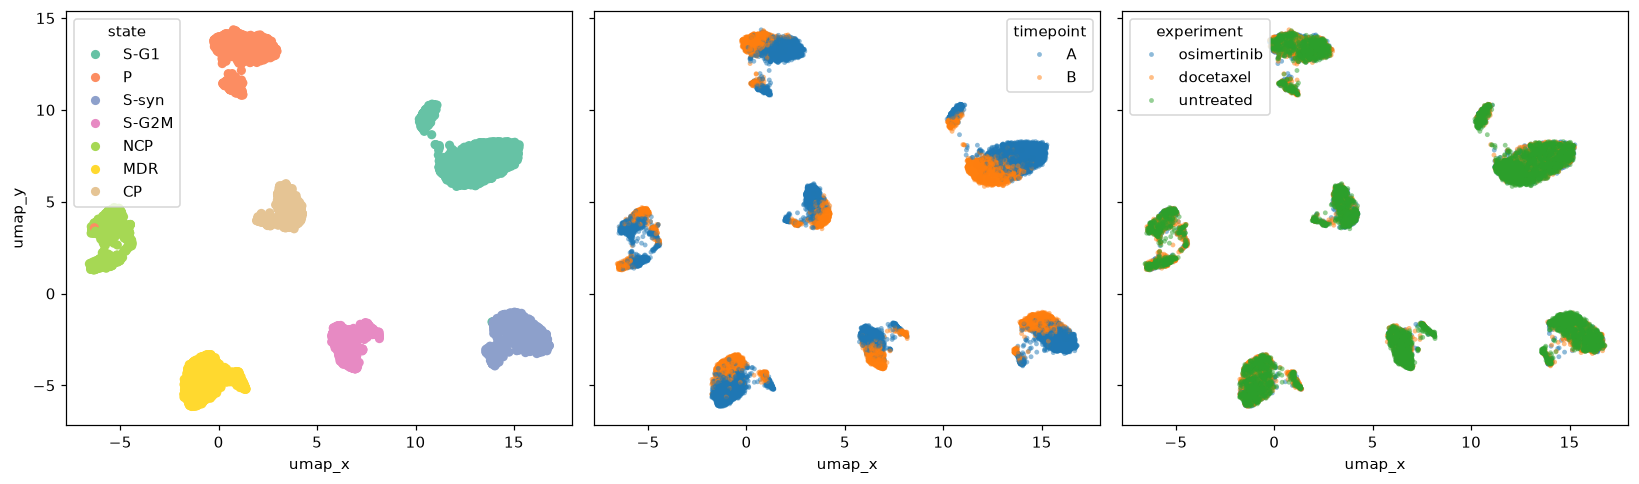

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

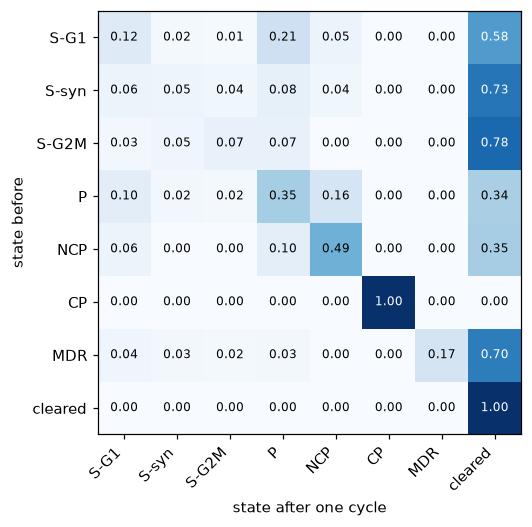

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

*Answer:*

Other than "Cleared", CP is absorbing, because p[CP, CP]=1. The other states do no come close, the next highest values are NCP at 0.49 and P at 0.35.

It means that Osemirtinib cannot kill cells that are in CP state. In other words, CP cells are resistant to osemirtinib.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

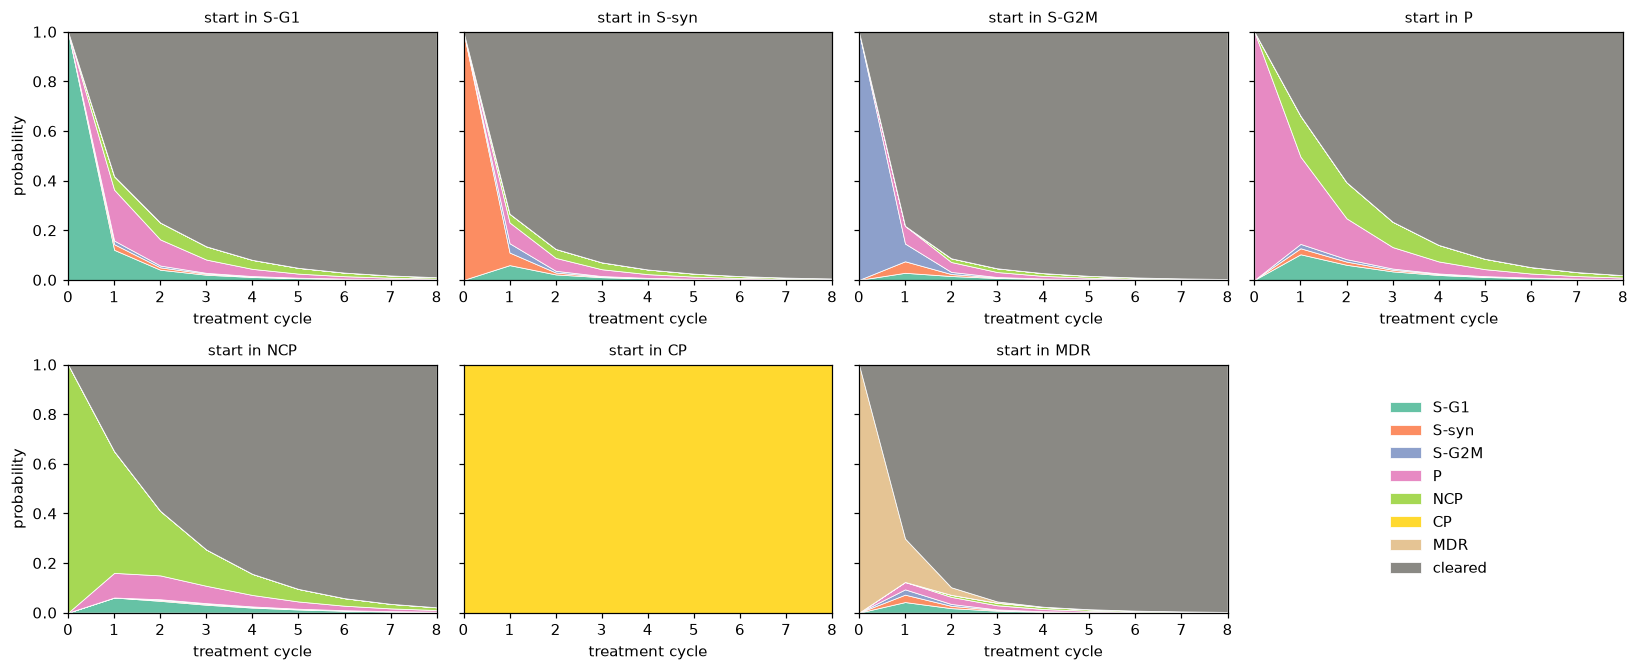

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



In [16]:
for s in STATES:
    traj = evolve(basis(s, P_hat), P_hat, 20)
    print(s, "-> cleared after 12 rounds:", round(traj[-1, -1], 4))

S-G1 -> cleared after 12 rounds: 1.0
S-syn -> cleared after 12 rounds: 1.0
S-G2M -> cleared after 12 rounds: 1.0
P -> cleared after 12 rounds: 1.0
NCP -> cleared after 12 rounds: 0.9999
CP -> cleared after 12 rounds: 0.0
MDR -> cleared after 12 rounds: 1.0


In [17]:
for s in STATES:
    traj = evolve(basis(s, P_hat), P_hat, 3)
    print(s, "-> cleared after 3 rounds:", round(traj[-1, -1], 4))

S-G1 -> cleared after 3 rounds: 0.8648
S-syn -> cleared after 3 rounds: 0.9293
S-G2M -> cleared after 3 rounds: 0.9533
P -> cleared after 3 rounds: 0.7656
NCP -> cleared after 3 rounds: 0.7457
CP -> cleared after 3 rounds: 0.0
MDR -> cleared after 3 rounds: 0.9549


Osemirtinib clears every type of cell (except for  CP) after 12 rounds and after 21 rounds almost everything is cleared (The value never reaches exactly 1). CP survives no matter how many rounds of OSemirtinib someone takes.

Out of the states that could be cleared, NCP lasts longest. That means that it is also the state that sticks around the longest. After three cycles, it is still the NCP that has the highest proprotion of alive cells.

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

pi_mix: {'S-G1': np.float64(0.247), 'S-syn': np.float64(0.148), 'S-G2M': np.float64(0.099), 'P': np.float64(0.153), 'NCP': np.float64(0.102), 'CP': np.float64(0.097), 'MDR': np.float64(0.153), 'cleared': np.float64(0.0)}
sums to: 1.0


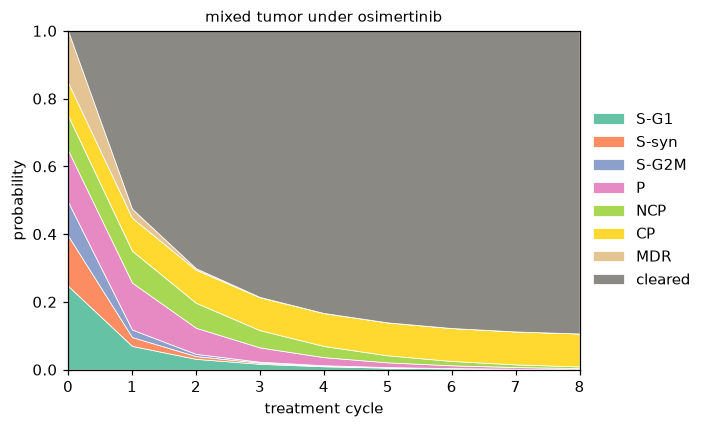

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


In [18]:
# Your code here
# Starting mix: the fraction of each state among all time-point-A cells (all 3 experiments)
pi_mix = (cells[cells.timepoint == "A"]["state"]
          .value_counts(normalize=True)        # fraction of cells in each state
          .reindex(OUTCOMES, fill_value=0)     # put in OUTCOMES order; "cleared" = 0
          .to_numpy())

print("pi_mix:", dict(zip(OUTCOMES, pi_mix.round(3))))
print("sums to:", pi_mix.sum())

# Evolve under 8 rounds of osimertinib and plot
traj_mix = evolve(pi_mix, P_hat, N_CYCLES)

fig, ax = plt.subplots(figsize=(6, 4))
plot_trajectory(traj_mix, ax, "mixed tumor under osimertinib")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

pd.DataFrame(traj_mix, columns=OUTCOMES).round(3)


<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

CP dominates the remaining cluster. It will never be cleared. No other cell comes close, the second dominating cell is NCP. All other cells except for CP will be almost completely cleared. 

After 8 cycles the tumor is 89% cleared and 10% CP, and the CP fraction (0.097) is exactly what we started with. This is because CP is absorbing in P (P[CP, CP] = 1, so CP cells never leave or die) and its column is 0 for every other state (no other cell becomes CP), so in the long run everything ends up in the two absorbing states, cleared and CP.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [19]:
##Add code here
def build_P(experiment):
    '''Transition matrix (8x8 DataFrame, with the "cleared" row) for one experiment.'''
    df = cells[cells["experiment"] == experiment]
    at_A = df[df.timepoint == "A"][["lineage_tag", "state"]]
    at_B = df[df.timepoint == "B"][["lineage_tag", "state"]]

    pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    pairs["state_B"] = pairs["state_B"].fillna("cleared")

    counts = (pd.crosstab(pairs.state_A, pairs.state_B)
                .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
    P = counts.div(counts.sum(axis=1), axis=0)
    P.loc["cleared"] = [0] * len(STATES) + [1]      # cleared stays cleared
    assert np.allclose(P.sum(axis=1), 1)
    return P

P_doc_df     = build_P("docetaxel")
P_holiday_df = build_P("untreated")    # the "drug holiday" is called "untreated" in the data

# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi     = P_hat.to_numpy()
P_doc     = P_doc_df.to_numpy()
P_holiday = P_holiday_df.to_numpy()


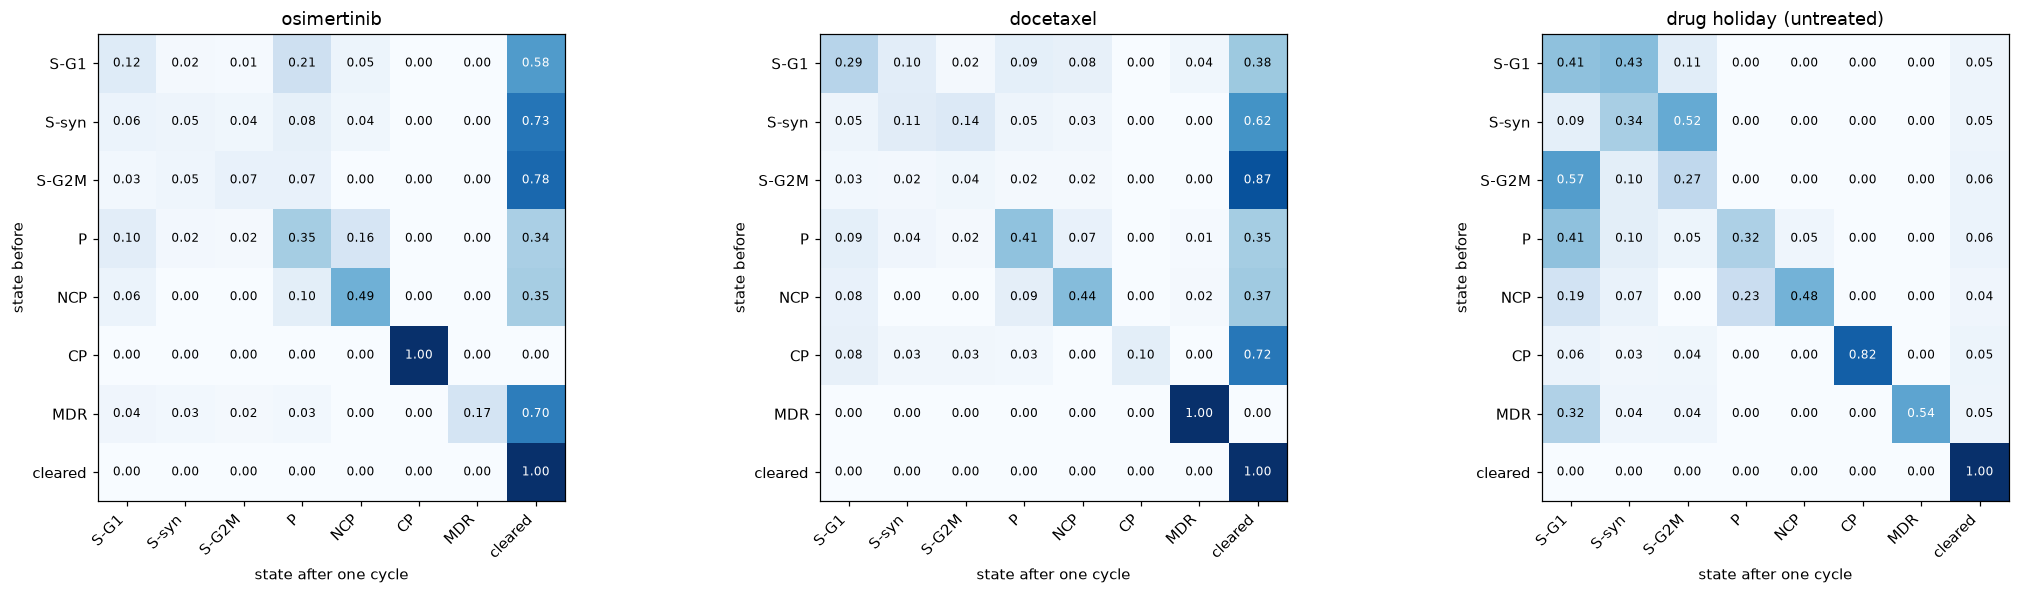

In [20]:
#Plot the transition matrices for docetaxel and the drug holiday.

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
show_matrix(P_hat,        "osimertinib", ax=axes[0])
show_matrix(P_doc_df,     "docetaxel",   ax=axes[1])
show_matrix(P_holiday_df, "drug holiday (untreated)", ax=axes[2])
plt.tight_layout()
plt.show()


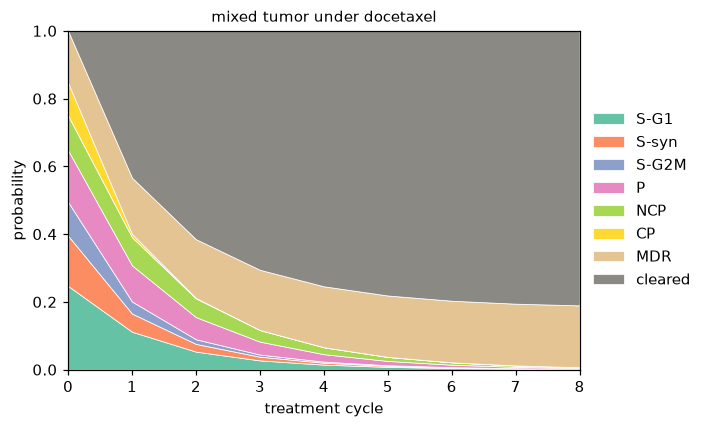

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


In [21]:
# Simulate the evolution of pi_mix under docetaxel 
traj_doc = evolve(pi_mix, P_doc, N_CYCLES)

fig, ax = plt.subplots(figsize=(6, 4))
plot_trajectory(traj_doc, ax, "mixed tumor under docetaxel")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

pd.DataFrame(traj_doc, columns=OUTCOMES).round(3)


*Answer questions in markdown here.*

##### 1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
Each drug has onc cell type it can't kill. In previous questions, we established that CP is resistant to Osimertinib. For Docetaxel, it is the MDR (P[MDR, MDR]=1). It ia important to note that, Osi kills 70% of MDR after a round, and Doce kills 72% of CP.

Under drug holiday no state is absorbing. Only about 5% of cells die in each round. What's surprising for me is that some cells convert to sensitive under drug holiday. P -> SG1 = 0.41 & MDR -> SG1 = 0.32. Meaning resting can actually let some resistant and persistant cells become cells that are easy to kill.

##### 2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?
After 8 rounds, about 81% of cells are cleared and about 18% are MDR. Everything else is close to 0.

It is also surpring to see that Docetaxel also creates resistance.In the chart above we see that the proportion of MDR cells increased from 0.153 to 0.183. Meaning that the drug pushes some cells into the one state it can't kill. This is worse than osimertinib, where CP just stayed at its starting 10%.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [22]:
def run_schedule(pi0, schedule):
    '''schedule = list of matrices, one per round. Returns one row per round (like evolve).'''
    traj = [np.asarray(pi0, dtype=float)]
    for P in schedule:
        traj.append(traj[-1] @ P)
    return np.array(traj)

def alive_after(pi0, schedule):
    '''Fraction of cells still alive at the end of the schedule.'''
    return 1 - run_schedule(pi0, schedule)[-1, -1]

DRUG = {"O": P_osi, "D": P_doc, "H": P_holiday}

def plan(code):
    '''Turn a string like "ODOD" into a list of matrices.'''
    return [DRUG[c] for c in code]

schedules = {
    "8x osimertinib (OOOOOOOO)": plan("OOOOOOOO"),
    "8x docetaxel (DDDDDDDD)":   plan("DDDDDDDD"),
    "alternate O->D (ODODODOD)": plan("ODODODOD"),
    "alternate D->O (DODODODO)": plan("DODODODO"),
    "doc + holiday (DHDHDHDH)":  plan("DHDHDHDH"),
    "osi + holiday (OHOHOHOH)":  plan("OHOHOHOH"),
    "4 osi then 4 doc":          plan("OOOODDDD"),
    "4 doc then 4 osi":          plan("DDDDOOOO"),
}

starts = {"mixed": pi_mix, **{f"all {s}": basis(s, P_hat) for s in STATES}}


In [23]:
table = pd.DataFrame({s_name: {sch_name: alive_after(pi0, sched)
                               for sch_name, sched in schedules.items()}
                      for s_name, pi0 in starts.items()})
print("Fraction of cells still alive after 8 rounds (lower is better):")
table.round(3).style.background_gradient(cmap="Reds", axis=None)

Fraction of cells still alive after 8 rounds (lower is better):


,mixed,all S-G1,all S-syn,all S-G2M,all P,all NCP,all CP,all MDR
8x osimertinib (OOOOOOOO),0.107000,0.011000,0.006000,0.004000,0.019000,0.022000,1.000000,0.003000
8x docetaxel (DDDDDDDD),0.190000,0.073000,0.012000,0.006000,0.055000,0.068000,0.010000,1.000000
alternate O->D (ODODODOD),0.009000,0.010000,0.005000,0.003000,0.017000,0.019000,0.006000,0.005000
alternate D->O (DODODODO),0.009000,0.011000,0.005000,0.002000,0.015000,0.017000,0.004000,0.007000
doc + holiday (DHDHDHDH),0.093000,0.066000,0.033000,0.012000,0.077000,0.090000,0.019000,0.311000
osi + holiday (OHOHOHOH),0.084000,0.030000,0.018000,0.013000,0.054000,0.068000,0.568000,0.014000
4 osi then 4 doc,0.015000,0.013000,0.007000,0.004000,0.023000,0.026000,0.035000,0.004000
4 doc then 4 osi,0.012000,0.013000,0.005000,0.002000,0.015000,0.017000,0.003000,0.024000


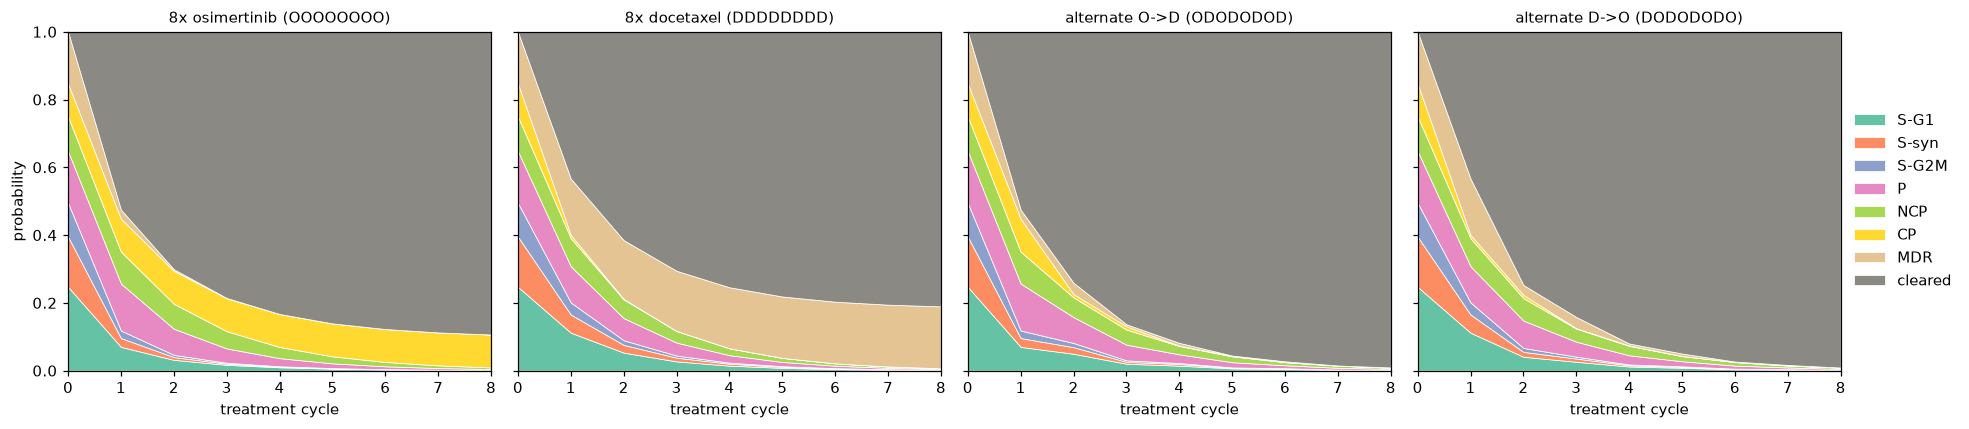

O->D alive: 0.0094
D->O alive: 0.0092


In [24]:
compare = ["8x osimertinib (OOOOOOOO)", "8x docetaxel (DDDDDDDD)",
           "alternate O->D (ODODODOD)", "alternate D->O (DODODODO)"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, name in zip(axes, compare):
    plot_trajectory(run_schedule(pi_mix, schedules[name]), ax, name)
axes[0].set_ylabel("probability")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

print("O->D alive:", round(alive_after(pi_mix, plan("ODODODOD")), 4))
print("D->O alive:", round(alive_after(pi_mix, plan("DODODODO")), 4))


In [25]:
holiday_test = {
    "8x docetaxel":       plan("DDDDDDDD"),
    "docetaxel + holiday": plan("DHDHDHDH"),
    "8x osimertinib":     plan("OOOOOOOO"),
    "osimertinib + holiday": plan("OHOHOHOH"),
}
pd.DataFrame({s: {n: alive_after(starts[s], sch) for n, sch in holiday_test.items()}
              for s in ["mixed", "all CP", "all MDR"]}).round(3)


,mixed,all CP,all MDR
8x docetaxel,0.190,0.010,1.000
docetaxel + holiday,0.093,0.019,0.311
8x osimertinib,0.107,1.000,0.003
osimertinib + holiday,0.084,0.568,0.014


In [26]:
def rounds_to_clear(pi0, pattern, target=0.01, max_rounds=40):
    '''Fewest rounds of a repeating pattern (e.g. "O" or "OD") until < target alive.'''
    for n in range(1, max_rounds + 1):
        if alive_after(pi0, plan((pattern * max_rounds)[:n])) < target:
            return n
    return "never"

pd.DataFrame({s: {p: rounds_to_clear(pi0, p) for p in ["O", "D", "OD", "DO"]}
              for s, pi0 in starts.items()}).T


,O,D,OD,DO
mixed,never,never,8,8
all S-G1,9,never,8,9
all S-syn,7,10,7,7
all S-G2M,6,6,6,6
all P,10,never,9,9
all NCP,10,never,10,10
all CP,never,9,8,7
all MDR,6,never,7,8


*Answer questions here.*

##### 1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib to an alternating schedule.
For the mixed tumor, neither drug alone is enough. After 8 rounds, 10.7% of cells are still aliv with Osi (mostly CP) and 19% with Doce (mostly MDR).Alternating the drugs leaves only about 0.9% alive. This works because each drug kills the cells the other one can't: Osi kills MDR and Doce kills CP.

##### 2. Does it matter if we start with osimertinib or docetaxel?
Not really for this tumor. Starting with Osi leaves 0.0094 alive and starting with Doce leaves 0.0092. Both need 8 rounds to get below 1% alive. It only matters a little when the tumor is mostly one type. For example, an all-CP tumor clears one round faster if we start with Doce (7 vs 8), and an all-MDR tumor clears one round faster if we start with Osi (7 vs 8). So it is better to start with the drug that kills the main cell type.

##### 3. In what situation would a drug holiday help clear the tumor?
A holiday helps when we only use one drug. With Doce alone, 19% of the mixed tumor is alive after 8 rounds, but with Doce + holiday it drops to 9.3%. With Osi alone, an all CP tumor never dies (100% alive);but with Osi & holiday it drops down at 56.8%. The reason is that during the holiday, resistant cells turns back into sensitive cells (for exsmple MDR -> S-G1 = 0.32), and then the next dose kills them. The holiday never beat alternating the drugs, though. 

##### 4. Treatment prescription
I counted a tumor as "cleared" when less than 1% of cells are alive (it never reaches exactly 0).

| Tumor is mostly... | Treatment | Rounds |
|---|---|---|
| S-G2M | Osi, Doce, or alternating | 6 |
| S-syn | Osi or alternating | 7 |
| S-G1 | Alternating, start with Osi | 8 |
| P | Alternating | 9 |
| NCP | Osi or alternating | 10 |
| CP | Alternating, start with Doce | 7 |
| MDR | Osi | 6 |
| Mixed / unknown | Alternating (either order) | 8 |

The general patterns:
- Never use Doce alone on sensitive cells or persisters. It slowly turns them into MDR, which it can't kill, so they never clear.
- Never use Osi alone if there is CP, and never use Doce alone if there is MDR.
- When we don't know what the tumor is made of, alternating is the safest choice. It clears every tumor type in 10 rounds or fewer.
- Persisters (P and NCP) take the longest (9-10 rounds) because they stay in their state for a few rounds before dying.


## 6 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [27]:
rng = np.random.default_rng(100)

In [28]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [29]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

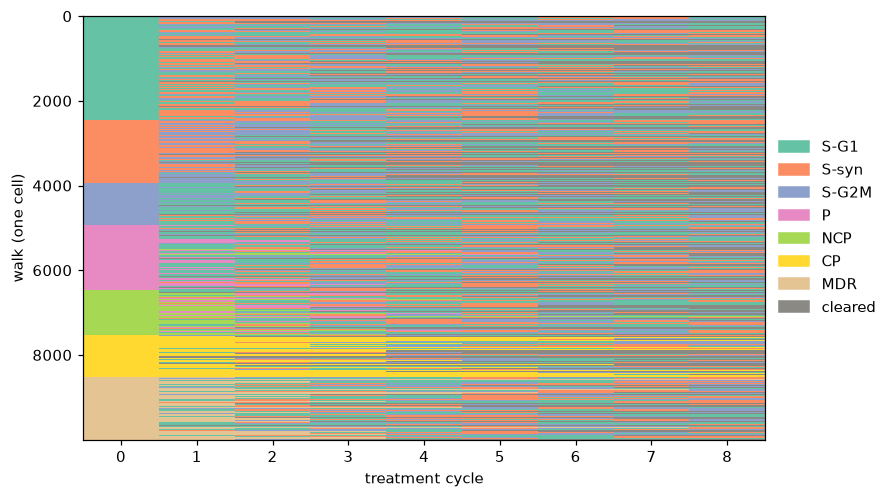

In [30]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [31]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

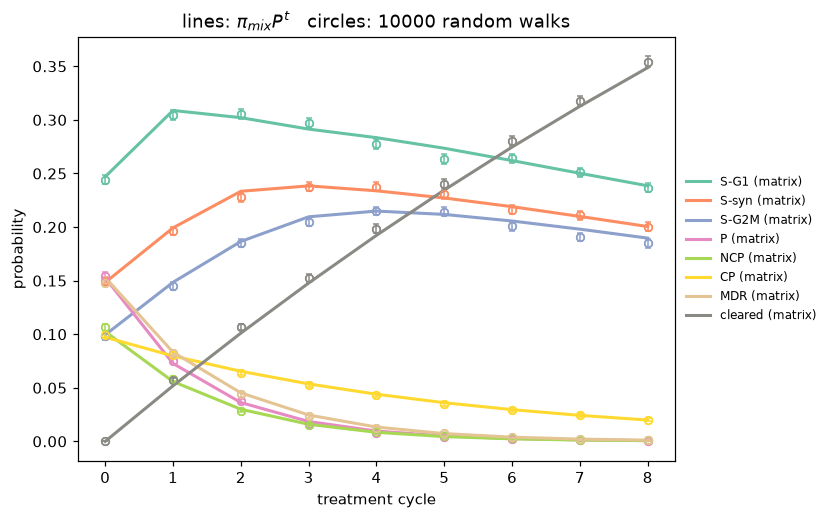

In [32]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

*Answer:*

With 10 k  walks, the gap between the circles and the lines becomes much smaller( about 10 times smaller than with 100 walks). This is because averging more random walks gets rid of the randomness. The error shrinks like 1/sq root of N, so 100 times more walks gives about 10 times less error.


## 7. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [33]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

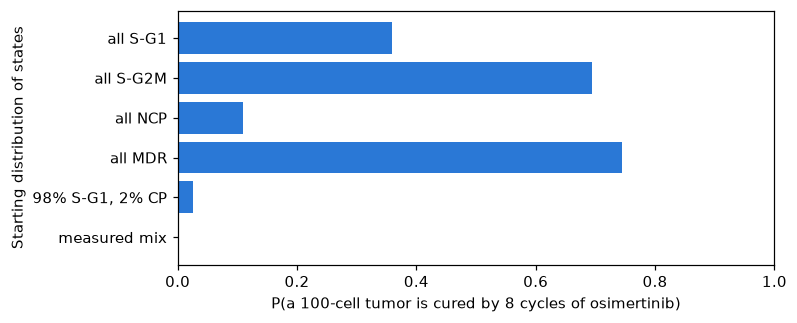

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.360,1.030,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.135,0.000
all MDR,0.745,0.280,0.000
"98% S-G1, 2% CP",0.025,3.210,0.639
measured mix,0.000,10.665,0.919


In [34]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)


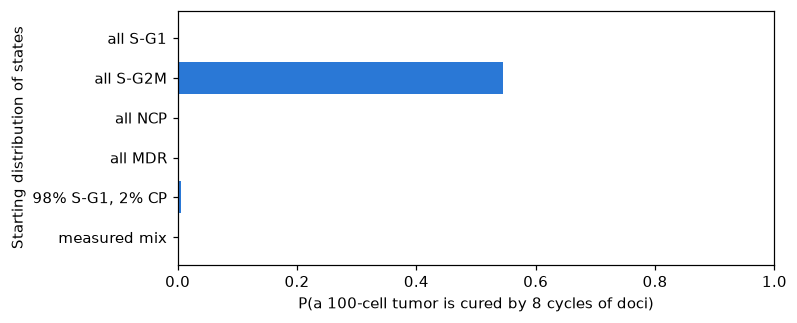

,P(cured),mean surviving cells,share of survivors that are MDR
start,,,
all S-G1,0.000,7.81,0.862
all S-G2M,0.545,0.61,0.631
all NCP,0.000,6.70,0.796
all MDR,0.000,100.00,1.000
"98% S-G1, 2% CP",0.005,6.99,0.867
measured mix,0.000,18.97,0.964


In [35]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of Doci
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are MDR":
                     (finals == OUTCOMES.index("MDR")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of doci)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

*Answer:*

Docetaxel does much worse than the osi. The only tumor with a real chance of being cured is when it is"all S-G2M" (P(cured) = 0.58, vs 0.72 with osi). Every other tumor is almost never cured, even all S-G1 (0.005 vs 0.38 with Osi). Majority of the ones that survived is MDR (72-96%), because doce turns some cells into MDR, which it can't kill. An all-MDR tumor is never cured and all 100 cells survive, just like allCP under osi. the measured mix is never cured by either drug, but docetaxel leaves more cells alive (18.7 vs 11.2).


## 8. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [36]:
PERSISTER = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]
DRUG = {"O": P_osi, "D": P_doc, "H": P_holiday}
rng = np.random.default_rng(5030)

def simulate_walks(pi0, schedule, n_cells, rng):
    '''Run n_cells random walks at once (same inverse-CDF method as step()).
    schedule = list of matrices, one per cycle. Returns array (n_cells, n_cycles+1).'''
    n_states = len(pi0)
    state = rng.choice(n_states, size=n_cells, p=pi0)        # starting states
    walks = [state]
    for P in schedule:
        cum = np.cumsum(P[state], axis=1)                      # each cell's CDF row
        u = rng.random((n_cells, 1))                           # one U per cell
        state = np.minimum((u > cum).sum(axis=1), n_states - 1)  # first state with CDF > U
        walks.append(state)
    return np.array(walks).T

def longest_persister_run(walks):
    '''For each walk, the longest number of consecutive time points spent in P or NCP.'''
    in_pers = np.isin(walks, PERSISTER)
    run = np.zeros(len(walks), dtype=int)
    best = np.zeros(len(walks), dtype=int)
    for t in range(walks.shape[1]):
        run = np.where(in_pers[:, t], run + 1, 0)   # keep counting, or reset to 0
        best = np.maximum(best, run)
    return best

def simulate_tumors(pi0, pattern, n_cycles, n_tumors=100, n_cells=1000, rng=rng):
    '''Fraction of permanently resistant cells (3+ cycles in P/NCP) in each of n_tumors tumors.'''
    schedule = [DRUG[c] for c in (pattern * n_cycles)[:n_cycles]]
    return np.array([np.mean(longest_persister_run(simulate_walks(pi0, schedule, n_cells, rng)) >= 3)
                     for _ in range(n_tumors)])

# --- Osimertinib, 8 cycles: mean +/- SEM and comparison to 10% ---
fr_osi = simulate_tumors(pi_mix, "O", 8)
mean, sem = fr_osi.mean(), fr_osi.std(ddof=1) / np.sqrt(len(fr_osi))
lo, hi = mean - 1.96 * sem, mean + 1.96 * sem
print(f"Osimertinib, 8 cycles: PR fraction = {mean:.3f} ± {sem:.4f} (SEM)")
print(f"95% CI: [{lo:.3f}, {hi:.3f}]  ->", "above 10%" if lo > 0.10 else "below 10%" if hi < 0.10 else "includes 10%")


Osimertinib, 8 cycles: PR fraction = 0.115 ± 0.0010 (SEM)
95% CI: [0.113, 0.117]  -> above 10%


In [37]:
treatments = {"Osimertinib alone": "O", "Docetaxel alone": "D",
              "Alternating OD": "OD", "Docetaxel + holiday": "DH"}
cycle_list = [4, 8, 12, 16]

pct_over = {}
for name, pattern in treatments.items():
    pct_over[name] = {n: 100 * np.mean(simulate_tumors(pi_mix, pattern, n) > 0.10)
                      for n in cycle_list}

print("% of tumors with more than 10% permanently resistant cells:")
pd.DataFrame(pct_over).T


% of tumors with more than 10% permanently resistant cells:


,4,8,12,16
Osimertinib alone,86.0,94.0,88.0,96.0
Docetaxel alone,5.0,17.0,18.0,17.0
Alternating OD,45.0,65.0,80.0,76.0
Docetaxel + holiday,0.0,49.0,55.0,64.0


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

*Answer:*

Under osimertinib for 8 cycles, 11.5% ± 0.1% (SEM) of cells become permanently resistant. The 95% CI [11.3%, 11.7%] is fully above 10%.

Percentage of tumors with more than 10% PR cells:

| Treatment | 4 cycles | 8 cycles | 12 cycles | 16 cycles |
|---|---|---|---|---|
| Osimertinib alone | 86% | 94% | 88% | 96% |
| Docetaxel alone | 5% | 17% | 18% | 17% |
| Alternating OD | 45% | 65% | 80% | 76% |
| Docetaxel + holiday | 0% | 49% | 55% | 64% |

Osimertinib alone is the worst because it pushes many cells into P and NCP. Docetaxel alone is the best. As the number of cycles increases, the percentage goes up because cells have more time to get stuck as persisters. After about 8-12 cycles it levels off, since most cells are already dead. The small ups and downs (e.g. 94% → 88% → 96%) are random noise, because the PR fractions are very close to the 10% line.
